# Soal 16 — MLP untuk Prediksi Horsepower (Auto MPG)

**Nama:** Marsa Naufal  **NIM:** 04231047  **Seed:** 47 (dua digit terakhir NIM)
**Dataset:** D8 — Auto MPG, UCI (398 mobil tahun 1970–1982)
**Library:** `PyTorch` (MLP), `pandas`/`numpy`/`scikit-learn` (preprocessing dan metrik).

Alur: *Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Interpretasi Hasil*. Jawaban butir (a)–(d) ditandai **Jawaban 16a–16d**.

## 1. Business Understanding

**Latar belakang.** Data spesifikasi kendaraan sering tidak lengkap. Di dataset ini pun ada mobil yang nilai horsepower-nya kosong. Horsepower penting untuk klasifikasi pajak, asuransi, dan perbandingan performa. Kalau horsepower bisa ditebak akurat dari spesifikasi lain yang lebih mudah didapat (berat, kapasitas mesin, jumlah silinder, konsumsi BBM), data yang bolong bisa dilengkapi dengan andal. Ibaratnya montir berpengalaman yang bisa menebak tenaga mesin hanya dari melihat ukuran mesin dan bobot mobilnya.

**Rumusan masalah.**
1. Seberapa akurat MLP dua hidden layer memprediksi horsepower dari fitur lain?
2. Apakah model mengalami overfitting atau underfitting, dan apakah regularisasi bisa memperbaikinya?

**Tujuan.** Membangun pipeline preprocessing tanpa *data leakage*, melatih MLP dengan early stopping, dan mengevaluasinya dengan MAE/RMSE/R² di test set.

**Kriteria kesuksesan.**

| Kriteria | Ambang |
|---|---|
| R² test | ≥ 0.85 |
| MAE test | ≤ 10 hp (≈ 25% dari std horsepower ~38 hp) |
| Tidak overfit berat | RMSE test ≤ 1.3 × RMSE train |
| Lebih baik dari / setara baseline regresi linear | RMSE test MLP ≤ RMSE linear |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy, time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 47
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)              # CPU satu thread: hasil identik setiap dijalankan ulang
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 2. Data Understanding

### 2.1 Memuat data dan sampel
File dipisah spasi/tab, nama mobil diapit tanda kutip, dan nilai hilang ditulis `?`.

In [2]:
cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "car_name"]
df_raw = pd.read_csv("data/auto+mpg/auto-mpg.data", sep=r"\s+", header=None, names=cols, na_values="?")
print("Ukuran data:", df_raw.shape)
df_raw.head(20)

Ukuran data: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino
5,15.0,8,429.0,198.0,4341.0,10.0,70,1,ford galaxie 500
6,14.0,8,454.0,220.0,4354.0,9.0,70,1,chevrolet impala
7,14.0,8,440.0,215.0,4312.0,8.5,70,1,plymouth fury iii
8,14.0,8,455.0,225.0,4425.0,10.0,70,1,pontiac catalina
9,15.0,8,390.0,190.0,3850.0,8.5,70,1,amc ambassador dpl


### 2.2 Atribut dan tipe data

| Kolom | Arti | Tipe |
|---|---|---|
| mpg | konsumsi BBM, mil per galon (makin besar makin irit) | numerik kontinu |
| cylinders | jumlah silinder (3, 4, 5, 6, 8) | numerik diskret / ordinal |
| displacement | kapasitas mesin, inci kubik | numerik kontinu |
| **horsepower** | tenaga mesin, hp (**target**) | numerik kontinu, ada 6 missing |
| weight | berat mobil, lbs | numerik kontinu |
| acceleration | waktu 0–60 mph, detik (makin kecil makin cepat) | numerik kontinu |
| model_year | tahun model (70–82) | numerik diskret |
| origin | asal: 1 = USA, 2 = Eropa, 3 = Jepang | **kategorikal** (angka hanya kode) |
| car_name | nama mobil | teks unik, **tidak dipakai** sesuai soal |

In [3]:
df_raw.info()
display(df_raw.describe().T.round(2))
print("Missing value per kolom:", df_raw.isna().sum().to_dict())
print("Baris duplikat:", df_raw.duplicated().sum())
print("Komposisi origin:", df_raw["origin"].value_counts().sort_index().to_dict())
display(df_raw[df_raw["horsepower"].isna()])

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0
origin,398.0,1.57,0.80,1.0,1.00,1.0,2.00,3.0


Missing value per kolom: {'mpg': 0, 'cylinders': 0, 'displacement': 0, 'horsepower': 6, 'weight': 0, 'acceleration': 0, 'model_year': 0, 'origin': 0, 'car_name': 0}
Baris duplikat: 0
Komposisi origin: {1: 249, 2: 70, 3: 79}


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [4]:
num = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
q1, q3 = df_raw[num].quantile(.25), df_raw[num].quantile(.75); iqr = q3 - q1
print("Outlier 1.5×IQR per kolom:\n", ((df_raw[num] < q1 - 1.5 * iqr) | (df_raw[num] > q3 + 1.5 * iqr)).sum().to_string())

Outlier 1.5×IQR per kolom:
 mpg              1
cylinders        0
displacement     0
horsepower      10
weight           0
acceleration     7
model_year       0


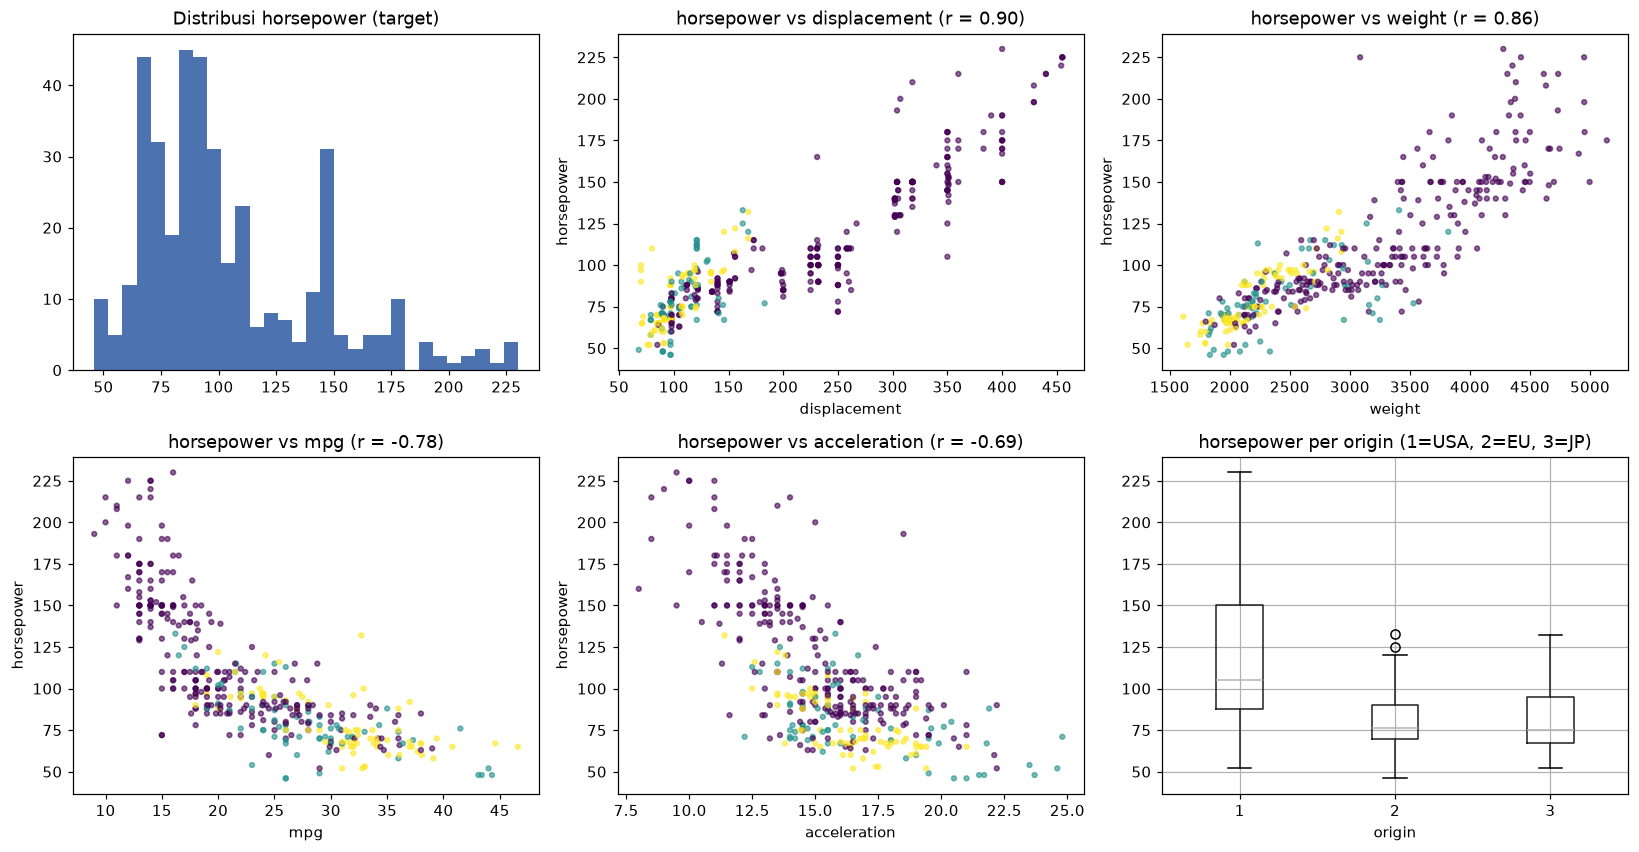

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].hist(df_raw["horsepower"].dropna(), bins=30, color="#4C72B0"); axes[0, 0].set_title("Distribusi horsepower (target)")
for ax, c in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], ["displacement", "weight", "mpg", "acceleration"]):
    ax.scatter(df_raw[c], df_raw["horsepower"], s=10, alpha=.6, c=df_raw["origin"], cmap="viridis")
    ax.set_xlabel(c); ax.set_ylabel("horsepower"); ax.set_title(f"horsepower vs {c} (r = {df_raw[[c,'horsepower']].corr().iloc[0,1]:.2f})")
df_raw.boxplot(column="horsepower", by="origin", ax=axes[1, 2]); axes[1, 2].set_title("horsepower per origin (1=USA, 2=EU, 3=JP)")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Interpretasi Data Understanding.**
- Ada **398 mobil, 9 kolom**, dan **0 duplikat**. Missing value hanya di **horsepower (6 baris)**, yaitu Ford Pinto, Ford Maverick, Renault LeCar, Ford Mustang Cobra, Renault 18i, dan AMC Concord. Karena horsepower adalah target, keenam baris ini tidak bisa dipakai latihan.
- Horsepower menyebar 46–230 hp (rata-rata 104, std 38.5) dan **miring ke kanan**: banyak mobil kecil 70–100 hp, sedikit mobil V8 besar. 10 outlier IQR semuanya mobil bertenaga besar (> 200 hp), bukan salah input.
- Hubungan dengan fitur lain **sangat kuat**:
  - displacement (r ≈ 0.90) dan weight (r ≈ 0.86) positif: mesin besar dan mobil berat → tenaga besar.
  - mpg (r ≈ −0.78) dan acceleration (r ≈ −0.69) negatif: mobil bertenaga besar lebih boros dan lebih cepat (waktu 0–60 lebih singkat).
- Scatter horsepower vs mpg terlihat **melengkung**, bukan garis lurus. Ini alasan MLP (yang bisa menangkap pola non-linear) layak dicoba dibanding regresi linear.
- Mobil USA (origin 1) bertenaga jauh lebih besar dan lebih bervariasi daripada Eropa dan Jepang.

## 3. Data Preparation

### Jawaban 16a — Preprocessing dan urutannya agar tidak terjadi *data leakage*

*Data leakage* itu seperti siswa yang sudah melihat soal ujian saat belajar: nilainya bagus, tapi bukan karena benar-benar paham. Dalam ML, kebocoran terjadi kalau **informasi dari data uji ikut dipakai saat menyiapkan atau melatih model**. Contohnya, mean untuk scaling dihitung dari seluruh data termasuk test. Urutan yang dipakai:

| Langkah | Kapan | Dari data mana | Alasan |
|---|---|---|---|
| 1. Tangani missing horsepower: **hapus 6 baris** | **sebelum split** (sesuai soal) | – | horsepower adalah **target**. Mengisi target dengan mean/median sama saja dengan mengarang kunci jawaban: model akan belajar dari label palsu, dan kalau baris itu jatuh ke test set, evaluasinya pun palsu. Menghapus tidak menghitung statistik apa pun, jadi aman dilakukan sebelum split. Hanya 1.5% data yang hilang. |
| 2. Buang `car_name` | sebelum split | – | sesuai soal; teks unik per mobil, tidak bisa digeneralisasi |
| 3. **Split 70/15/15** (seed 47) | – | – | train untuk belajar, validation untuk early stopping dan memilih varian model, test hanya sekali di akhir |
| 4. **One-hot `origin`** → 3 kolom (USA/Europe/Japan) | setelah split | kategori tetap (1, 2, 3) | angka 1/2/3 hanya kode. Kalau dibiarkan numerik, model mengira Jepang (3) = 3× USA (1). Kategorinya sudah diketahui dari dokumentasi, jadi tidak ada statistik yang bocor. |
| 5. **StandardScaler** untuk 6 fitur numerik | setelah split | **fit di train saja**, lalu transform val/test | MLP sensitif terhadap skala: berat (~3000) akan mendominasi silinder (~5). Mean/std harus dari train. |
| 6. **Standardisasi target** horsepower | setelah split | mean/std train | output network berada di kisaran ±2, sehingga gradien stabil. Prediksi dikembalikan ke satuan hp sebelum dihitung metriknya. |
| Outlier | dibiarkan | – | horsepower tinggi (sampai 230 hp) adalah mobil V8 asli, bukan salah input. Membuangnya membuat model gagal di mobil bertenaga besar. |

Kalau nanti dipakai untuk mengisi horsepower yang bolong, keenam baris yang dihapus tadi justru menjadi **data inferensi** (bagian 6).

In [6]:
df_missing = df_raw[df_raw["horsepower"].isna()].copy()       # disimpan untuk inferensi di akhir
df = df_raw.dropna(subset=["horsepower"]).drop(columns="car_name").reset_index(drop=True)
names = df_raw.dropna(subset=["horsepower"])["car_name"].reset_index(drop=True)
print("Setelah hapus missing target:", df.shape)

NUM_FEAT = ["mpg", "cylinders", "displacement", "weight", "acceleration", "model_year"]
idx = np.arange(len(df))
idx_tmp, idx_te = train_test_split(idx, test_size=0.15, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_tmp, test_size=0.15 / 0.85, random_state=SEED)
print(f"train={len(idx_tr)}, val={len(idx_va)}, test={len(idx_te)}")

scaler = StandardScaler().fit(df.loc[idx_tr, NUM_FEAT])          # FIT HANYA DI TRAIN
y_mu, y_sd = df.loc[idx_tr, "horsepower"].mean(), df.loc[idx_tr, "horsepower"].std()

def prep(frame):
    num_part = scaler.transform(frame[NUM_FEAT])
    onehot = np.stack([(frame["origin"] == k).astype(float) for k in (1, 2, 3)], axis=1)
    return np.hstack([num_part, onehot]).astype(np.float32)

X_tr, X_va, X_te = prep(df.loc[idx_tr]), prep(df.loc[idx_va]), prep(df.loc[idx_te])
y_tr, y_va, y_te = (df.loc[i, "horsepower"].values for i in (idx_tr, idx_va, idx_te))
FEAT_NAMES = NUM_FEAT + ["origin_USA", "origin_Europe", "origin_Japan"]
print("Bentuk input:", X_tr.shape, "| mean fitur train (≈0):", X_tr[:, :6].mean(0).round(3))
pd.DataFrame(X_tr[:5], columns=FEAT_NAMES).round(3)

Setelah hapus missing target: (392, 8)
train=274, val=59, test=59
Bentuk input: (274, 9) | mean fitur train (≈0): [-0. -0. -0. -0. -0. -0.]


,mpg,cylinders,displacement,weight,acceleration,model_year,origin_USA,origin_Europe,origin_Japan
0,-0.688,0.305,0.511,0.571,0.135,-0.236,1.0,0.0,0.0
1,1.277,-0.864,-0.929,-1.060,0.101,0.303,1.0,0.0,0.0
2,0.580,-0.864,-0.796,-0.436,1.379,1.650,1.0,0.0,0.0
3,-0.612,0.305,0.274,0.761,1.068,0.572,1.0,0.0,0.0
4,-1.702,1.474,1.050,1.652,-0.210,-1.583,1.0,0.0,0.0


## 4. Modeling

### Jawaban 16b — Rancangan MLP

```
input (9) → Linear(9→64) → ReLU → Linear(64→32) → ReLU → Linear(32→1)
```

| Komponen | Pilihan | Alasan |
|---|---|---|
| Hidden layer | **2 layer: 64 dan 32 neuron** | memenuhi syarat minimal 2 hidden layer. Bentuk "corong" 64 → 32 memadatkan informasi bertahap. Jumlah parameter (~2.800) masih wajar untuk 274 data latih, tidak terlalu raksasa. |
| Aktivasi hidden | **ReLU** | sederhana dan cepat, tidak membuat gradien menghilang seperti sigmoid. Memungkinkan model menangkap hubungan melengkung (misalnya horsepower vs mpg yang tidak lurus). |
| Output layer | **1 neuron, linear (tanpa aktivasi)** | regresi: hasilnya angka bebas, tidak dibatasi 0–1 seperti sigmoid |
| Loss | **MSE** | standar regresi. Kesalahan besar dihukum lebih berat, dan RMSE adalah akar MSE sehingga sejalan dengan metrik evaluasi. |
| Optimizer | **Adam, lr = 0.001**, batch 32 | Adam menyesuaikan langkah belajar tiap bobot secara otomatis, sehingga lebih "tahan banting" untuk data kecil daripada SGD biasa. lr 0.001 adalah default yang terbukti stabil. |
| Early stopping | pantau **loss validation**, *patience* 100 epoch, maksimal 3000 epoch, **kembalikan bobot terbaik** | berhenti ketika model mulai menghafal. Ibaratnya berhenti belajar ketika nilai try-out sudah tidak naik lagi. |

**Cara kerja singkat di PyTorch:** setiap *batch*, data dimasukkan ke network (*forward*), dihitung MSE-nya, lalu `loss.backward()` menghitung arah koreksi tiap bobot (*backpropagation*), dan `optimizer.step()` menggeser bobot sedikit ke arah yang mengurangi error.

In [7]:
class MLP(nn.Module):
    def __init__(self, n_in, h1=64, h2=32, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, h1), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(h2, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def to_t(a): return torch.tensor(a, dtype=torch.float32)
Xt_tr, Xt_va, Xt_te = to_t(X_tr), to_t(X_va), to_t(X_te)
yt_tr, yt_va = to_t((y_tr - y_mu) / y_sd), to_t((y_va - y_mu) / y_sd)

def predict_hp(model, Xt):
    model.eval()
    with torch.no_grad():
        return model(Xt).numpy() * y_sd + y_mu

def train_mlp(seed=SEED, dropout=0.0, weight_decay=0.0, lr=1e-3, max_epochs=3000, patience=100, batch=32):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLP(X_tr.shape[1], dropout=dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(seed)
    hist = {"train_rmse": [], "val_rmse": []}
    best, best_state, wait = np.inf, None, 0
    for ep in range(max_epochs):
        model.train()
        for b in torch.randperm(len(Xt_tr), generator=gen).split(batch):
            opt.zero_grad()
            loss = loss_fn(model(Xt_tr[b]), yt_tr[b])
            loss.backward()
            opt.step()
        tr = np.sqrt(mean_squared_error(y_tr, predict_hp(model, Xt_tr)))   # dalam satuan hp
        va = np.sqrt(mean_squared_error(y_va, predict_hp(model, Xt_va)))
        hist["train_rmse"].append(tr); hist["val_rmse"].append(va)
        if va < best - 1e-4:
            best, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    hist["best_epoch"] = int(np.argmin(hist["val_rmse"]))
    return model, hist

n_params = sum(p.numel() for p in MLP(X_tr.shape[1]).parameters())
print(MLP(X_tr.shape[1])); print("Jumlah parameter:", n_params)

MLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Jumlah parameter: 2753


In [8]:
t0 = time.time()
model, hist = train_mlp()
print(f"Selesai dalam {time.time()-t0:.1f} s | berhenti di epoch {len(hist['val_rmse'])}, "
      f"bobot terbaik dari epoch {hist['best_epoch']+1} (val RMSE = {min(hist['val_rmse']):.2f} hp)")

Selesai dalam 1.3 s | berhenti di epoch 128, bobot terbaik dari epoch 28 (val RMSE = 9.05 hp)


## 5. Evaluation

### Jawaban 16c — MAE / RMSE / R², plot prediksi-vs-aktual, dan *learning curve*

Sebagai pembanding, dilatih juga **regresi linear biasa** dengan preprocessing yang sama, untuk menjawab apakah MLP memang memberi nilai tambah.

In [9]:
def metrik(y, p, nama):
    return {"model / data": nama, "MAE (hp)": mean_absolute_error(y, p),
            "RMSE (hp)": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

lin = LinearRegression().fit(X_tr, y_tr)
p_tr, p_va, p_te = (predict_hp(model, X) for X in (Xt_tr, Xt_va, Xt_te))
hasil = pd.DataFrame([metrik(y_tr, p_tr, "MLP – train"), metrik(y_va, p_va, "MLP – validation"),
                      metrik(y_te, p_te, "MLP – TEST"), metrik(y_te, lin.predict(X_te), "Regresi linear – TEST")])
hasil.round(3)

,model / data,MAE (hp),RMSE (hp),R2
0,MLP – train,7.476,10.625,0.927
1,MLP – validation,6.297,9.046,0.948
2,MLP – TEST,5.396,7.103,0.951
3,Regresi linear – TEST,6.507,7.820,0.941


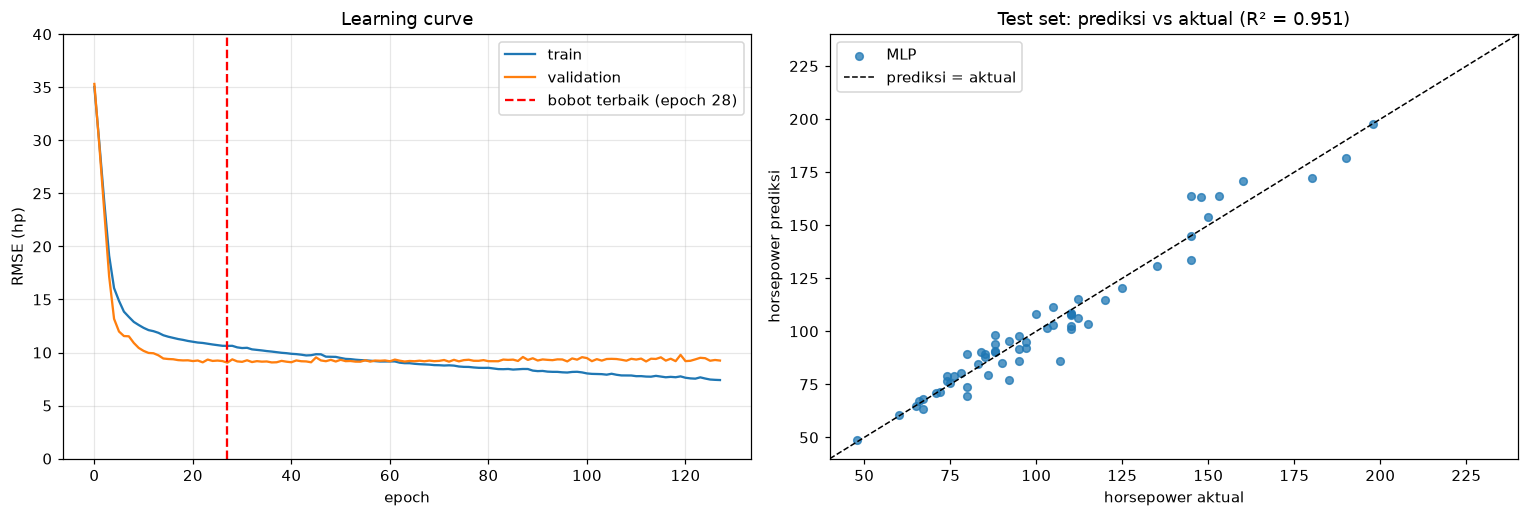

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(hist["train_rmse"], label="train", lw=1.5)
axes[0].plot(hist["val_rmse"], label="validation", lw=1.5)
axes[0].axvline(hist["best_epoch"], c="r", ls="--", label=f"bobot terbaik (epoch {hist['best_epoch']+1})")
axes[0].set_ylim(0, 40); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("RMSE (hp)")
axes[0].set_title("Learning curve"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].scatter(y_te, p_te, s=25, alpha=.75, label="MLP")
lim = [40, 240]; axes[1].plot(lim, lim, "k--", lw=1, label="prediksi = aktual")
axes[1].set_xlim(lim); axes[1].set_ylim(lim); axes[1].set_xlabel("horsepower aktual"); axes[1].set_ylabel("horsepower prediksi")
axes[1].set_title(f"Test set: prediksi vs aktual (R² = {r2_score(y_te, p_te):.3f})"); axes[1].legend()
plt.tight_layout(); plt.show()

**Hasil Jawaban 16c.**

| Data | MAE | RMSE | R² |
|---|---|---|---|
| Train | 7.48 hp | 10.63 hp | 0.927 |
| Validation | 6.30 hp | 9.05 hp | 0.948 |
| **Test** | **5.40 hp** | **7.10 hp** | **0.951** |
| Regresi linear (test) | 6.51 hp | 7.82 hp | 0.941 |

- Di test set, MLP rata-rata meleset **5.4 hp** dan menjelaskan **95.1%** variasi horsepower. MLP lebih baik dari regresi linear (RMSE 7.10 vs 7.82 hp, MAE turun ±17%), jadi lengkungan pola yang ditangkap MLP memberi nilai tambah, walau tidak dramatis karena hubungannya memang dominan linear.
- **Learning curve:** kedua kurva turun tajam di 10 epoch pertama. Setelah ~epoch 25, RMSE validation **mendatar di ~9 hp**, sementara RMSE train **terus turun** (sampai ~7.5 hp di epoch 128). Celah yang mulai terbuka ini adalah awal model "menghafal" data latih. Early stopping mengambil bobot terbaik di **epoch 28**, sebelum hafalan dimulai, lalu berhenti setelah 100 epoch tanpa perbaikan.
- **Plot prediksi-vs-aktual:** titik-titik rapat di sekitar garis diagonal untuk 50–130 hp. Penyebaran terbesar ada di mobil V8 140–200 hp, misalnya Ford LTD (aktual 148, prediksi 163). Data mobil bertenaga besar memang sedikit, dan di kelas ini mobil dengan spesifikasi mirip bisa punya horsepower berbeda (tuning mesin, era regulasi emisi).

### Jawaban 16d — Overfit atau underfit? Eksperimen mengubah satu elemen

**Diagnosis model awal** (lihat tabel dan learning curve di atas) dibahas di bawah. Untuk membuktikan dampak sebuah perubahan secara adil, **satu elemen saja yang diubah**: menambahkan **Dropout p = 0.2** setelah tiap hidden layer. Dropout mematikan 20% neuron secara acak di setiap langkah latihan, sehingga network tidak bisa bergantung pada segelintir neuron "penghafal". Ibaratnya belajar kelompok yang anggotanya bergantian absen: semua anggota jadi terpaksa paham materi.

Karena datanya kecil (59 sampel validation/test), hasil satu kali latihan bisa kebetulan bagus atau jelek. Jadi **kedua varian dilatih ulang dengan 5 seed** (47–51), lalu dibandingkan rata-rata dan simpangan bakunya. Varian dipilih berdasarkan **RMSE validation**. Test hanya dilaporkan, tidak dipakai memilih.

In [11]:
rows, curves = [], {}
for nama, kw in [("Awal (tanpa dropout)", {}), ("Dropout 0.2", {"dropout": 0.2})]:
    for s in range(SEED, SEED + 5):
        m, h = train_mlp(seed=s, **kw)
        curves[(nama, s)] = h
        ptr, pva, pte = (predict_hp(m, X) for X in (Xt_tr, Xt_va, Xt_te))
        rows.append({"varian": nama, "seed": s, "epoch_terbaik": h["best_epoch"] + 1,
                     "RMSE_train": np.sqrt(mean_squared_error(y_tr, ptr)),
                     "RMSE_val": np.sqrt(mean_squared_error(y_va, pva)),
                     "RMSE_test": np.sqrt(mean_squared_error(y_te, pte)),
                     "MAE_test": mean_absolute_error(y_te, pte), "R2_test": r2_score(y_te, pte)})
exp = pd.DataFrame(rows)
exp["gap_val-train"] = exp["RMSE_val"] - exp["RMSE_train"]
ringkasan = exp.groupby("varian")[["RMSE_train", "RMSE_val", "RMSE_test", "MAE_test", "R2_test", "gap_val-train", "epoch_terbaik"]].agg(["mean", "std"])
ringkasan.round(3)

RMSE_train        RMSE_val        RMSE_test        MAE_test        R2_test        gap_val-train        epoch_terbaik        
                           mean    std     mean    std      mean    std     mean    std    mean    std          mean    std          mean     std
varian                                                                                                                                           
Awal (tanpa dropout)      9.708  0.743    9.060  0.165     7.351  0.373    5.713  0.342   0.948  0.005        -0.648  0.725          47.2  19.228
Dropout 0.2               8.988  0.790    8.856  0.381     6.967  0.302    5.479  0.248   0.953  0.004        -0.132  0.439         127.6  78.561

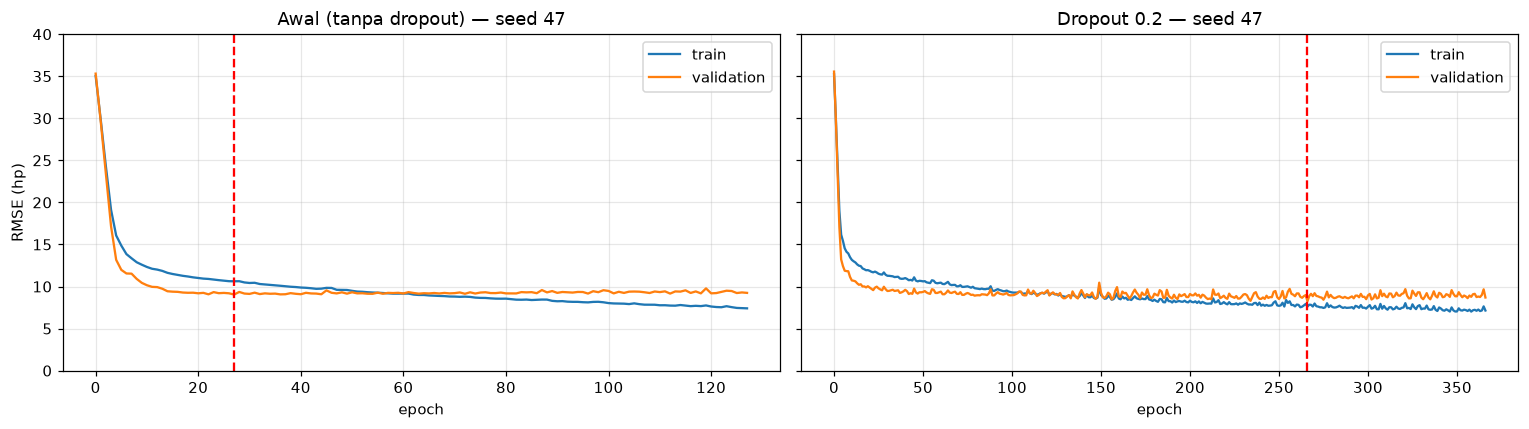

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, nama in zip(axes, ["Awal (tanpa dropout)", "Dropout 0.2"]):
    h = curves[(nama, SEED)]
    ax.plot(h["train_rmse"], label="train"); ax.plot(h["val_rmse"], label="validation")
    ax.axvline(h["best_epoch"], c="r", ls="--"); ax.set_ylim(0, 40); ax.set_title(f"{nama} — seed {SEED}")
    ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("RMSE (hp)"); plt.tight_layout(); plt.show()

**Hasil Jawaban 16d.**

**Diagnosis model awal: tidak overfit, cenderung "pas" sampai sedikit underfit.**
- RMSE train (10.6) justru **lebih besar** dari validation (9.0) dan test (7.1). Kalau overfit, polanya terbalik (train jauh lebih kecil). Penyebabnya bukan karena data latih lebih sulit; porsi mobil > 202 hp di train (2.9%) dan validation (3.4%) hampir sama. Ada tiga alasan:
  - Saat bobot terbaik diambil (epoch 28), model **belum selesai mempelajari data latih** (RMSE train masih turun), jadi wajar error train masih tinggi.
  - RMSE validation **sedikit optimis**, karena early stopping justru memilih epoch yang paling bagus untuk validation.
  - **Test set kebetulan lebih mudah**: tidak ada satu pun mobil > 202 hp, dan sebarannya lebih sempit (std 32.5 vs 39.5 di train). Jadi RMSE test 7.1 hp kemungkinan sedikit terlalu optimis untuk mobil bertenaga besar.
- Learning curve memperlihatkan bahwa **seandainya dilatih terus**, model akan overfit (train turun, val stagnan). Tetapi early stopping memotongnya di epoch 28, sehingga model akhir **tidak overfit**.
- Masalah yang tersisa justru early stopping **terlalu cepat**: bobot terbaik rata-rata sudah diambil di epoch ~47 (5 seed) karena kurva validation datar dan sedikit naik-turun, sehingga model belum memakai seluruh kapasitasnya.

**Eksperimen Dropout 0.2 (5 seed, rata-rata ± std):**

| Varian | RMSE train | RMSE val | RMSE test | MAE test | R² test | Epoch terbaik |
|---|---|---|---|---|---|---|
| Awal | 9.71 ± 0.74 | 9.06 ± 0.17 | 7.35 ± 0.37 | 5.71 ± 0.34 | 0.948 | 47 |
| **Dropout 0.2** | 8.99 ± 0.79 | **8.86** ± 0.38 | **6.97** ± 0.30 | **5.48** ± 0.25 | **0.953** | 128 |

- Dropout **menurunkan RMSE validation** (9.06 → 8.86 hp), sehingga sesuai aturan seleksi berbasis validation varian ini lebih baik. Di test pun membaik (7.35 → 6.97 hp; MAE 5.71 → 5.48 hp).
- **Mekanismenya:** dropout membuat latihan lebih "berisik", sehingga model tidak bisa cepat menghafal. Kurva validation menurun lebih lama dan bobot terbaik baru tercapai di epoch ~128 (vs 47). Model sempat belajar pola yang lebih halus tanpa terjerumus ke hafalan. Terlihat di plot kanan: kurva train dan val berjalan berdampingan jauh lebih lama.
- **Kritik jujur:** perbaikannya **kecil**, sekitar 0.2–0.4 hp, setara 1× simpangan baku antar-seed. Jadi dropout membantu secara konsisten di rata-rata, tetapi untuk dataset sekecil ini (59 sampel test) bedanya belum bisa disebut besar. Dengan satu seed saja kesimpulannya bisa terbalik. Itulah sebabnya eksperimen diulang 5 seed.

**Kesimpulan 16d:** model awal tidak overfit (berkat early stopping), tetapi berhenti terlalu dini. Regularisasi dropout 0.2 memberi ruang latihan lebih panjang dan menurunkan error validation maupun test secara konsisten walau kecil.

## 6. Interpretasi Hasil

### 6.1 Prediksi vs aktual pada 20 mobil di test set

In [13]:
tab = df.loc[idx_te, ["cylinders", "displacement", "weight", "mpg"]].copy()
tab.insert(0, "car_name", names.loc[idx_te].values)
tab["hp_aktual"] = y_te
tab["hp_prediksi"] = p_te.round(1)
tab["error"] = (tab["hp_prediksi"] - tab["hp_aktual"]).round(1)
tab.head(20)

,car_name,cylinders,displacement,weight,mpg,hp_aktual,hp_prediksi,error
5,ford galaxie 500,8,429.0,4341.0,15.0,198.0,197.9,-0.1
353,mazda 626,4,120.0,2635.0,31.6,74.0,76.4,2.4
272,audi 5000,5,131.0,2830.0,20.3,103.0,101.6,-1.4
286,dodge st. regis,8,318.0,3830.0,18.2,135.0,130.6,-4.4
157,ford ltd,8,351.0,4657.0,14.0,148.0,163.1,15.1
168,pontiac astro,4,140.0,2592.0,23.0,78.0,80.2,2.2
291,vw rabbit custom,4,89.0,1925.0,31.9,71.0,70.7,-0.3
60,ford pinto runabout,4,122.0,2226.0,21.0,86.0,79.6,-6.4
349,volkswagen jetta,4,105.0,2190.0,33.0,74.0,78.8,4.8
282,dodge aspen 6,6,225.0,3360.0,20.6,110.0,101.1,-8.9


### 6.2 Inferensi pada data yang benar-benar baru: 6 mobil dengan horsepower kosong
Keenam mobil ini tidak punya label sama sekali, jadi tidak pernah dilihat model. Inilah kegunaan nyata model: **melengkapi data yang bolong**. Karena tidak ada kunci jawaban, kewajarannya dicek dengan membandingkan ke horsepower rata-rata mobil di data latih yang jumlah silindernya sama.

In [14]:
inf = df_missing[["car_name", "cylinders", "displacement", "weight", "mpg", "model_year"]].copy()
inf["hp_prediksi_MLP"] = predict_hp(model, to_t(prep(df_missing))).round(1)
rata_silinder = df.loc[idx_tr].groupby("cylinders")["horsepower"].agg(["mean", "min", "max"]).round(1)
inf = inf.join(rata_silinder.add_prefix("hp_train_silinder_sama_"), on="cylinders")
inf

,car_name,cylinders,displacement,weight,mpg,model_year,hp_prediksi_MLP,hp_train_silinder_sama_mean,hp_train_silinder_sama_min,hp_train_silinder_sama_max
32,ford pinto,4,98.0,2046.0,25.0,71,69.5,77.6,46.0,115.0
126,ford maverick,6,200.0,2875.0,21.0,74,82.2,101.5,72.0,165.0
330,renault lecar deluxe,4,85.0,1835.0,40.9,80,57.1,77.6,46.0,115.0
336,ford mustang cobra,4,140.0,2905.0,23.6,80,101.2,77.6,46.0,115.0
354,renault 18i,4,100.0,2320.0,34.5,81,75.0,77.6,46.0,115.0
374,amc concord dl,4,151.0,3035.0,23.0,82,83.3,77.6,46.0,115.0


**Interpretasi uji akhir.**
- **Test set:** pada 20 mobil, kebanyakan prediksi meleset < 7 hp. Contohnya Ford Galaxie 500 (198 vs 197.9) dan VW Rabbit Custom (71 vs 70.7). Error terbesar ada pada Ford LTD (+15 hp), Chevrolet Citation (−11.5), dan Monte Carlo Landau (−11.4). Ini mobil yang horsepower-nya "menyimpang" dari pola berat-mesin umum. Perlu dicatat, test set ini **tidak memuat satu pun mobil > 202 hp** (maksimum 198 hp). Kemampuan model untuk mobil bertenaga sangat besar belum benar-benar teruji, dan di data validation (yang memuat 2 mobil seperti itu) error-nya memang lebih besar.
- **Inferensi 6 mobil tanpa label:** semua prediksi berada **di dalam rentang** horsepower mobil latih dengan jumlah silinder yang sama.
  - Renault LeCar (mobil kecil, 85 in³, sangat irit 40.9 mpg) → **57 hp**, di sisi bawah kelas 4 silinder. Masuk akal.
  - Ford Mustang Cobra (4 silinder tetapi berat 2905 lbs dan mesin 140 in³) → **101 hp**, di sisi atas kelas 4 silinder.
  - Model mengikuti logika fisik: mesin lebih besar dan mobil lebih berat menghasilkan prediksi tenaga lebih tinggi. Kunci jawaban sebenarnya tidak ada di dataset, jadi ini hanya cek kewajaran.

### 6.2 Pengecekan kriteria kesuksesan

| Kriteria | Target | Hasil (model awal, seed 47) | Status |
|---|---|---|---|
| R² test | ≥ 0.85 | 0.951 | ✅ |
| MAE test | ≤ 10 hp | 5.40 hp | ✅ |
| Tidak overfit berat | RMSE test ≤ 1.3 × RMSE train | 7.10 ≤ 13.8 | ✅ |
| ≤ baseline linear | RMSE test MLP ≤ linear | 7.10 < 7.82 | ✅ |

### 6.3 Kesimpulan
1. Pipeline tanpa kebocoran: buang 6 baris target kosong sebelum split, lalu one-hot `origin` dan scaler yang di-fit hanya di train. Hasilnya evaluasi yang jujur.
2. MLP 9 → 64 → 32 → 1 (ReLU, MSE, Adam, early stopping) memprediksi horsepower dengan **MAE 5.4 hp, RMSE 7.1 hp, R² 0.951** di test, lebih baik dari regresi linear.
3. Model tidak overfit karena early stopping. Dropout 0.2 sedikit memperbaiki generalisasi (RMSE test rata-rata 7.35 → 6.97 hp dari 5 seed) karena memungkinkan latihan lebih lama tanpa menghafal.
4. Keterbatasan: data kecil (392 mobil), sehingga metrik di 59 sampel test cukup bervariasi antar-seed, dan mobil bertenaga besar masih paling sulit diprediksi. Pengembangan: *k-fold cross-validation* untuk estimasi yang lebih stabil, atau transformasi log pada target untuk menangani kemiringan distribusi.